# V2 Policy Features

## 목적

2021-07 ~ 2026-06 서울 아파트 거래에 **그 시점에 공개되어 있던 부동산 정책 정보**를 붙인다.
V1(`07_policy_eda_feature_engineering`)의 정책 상태 5개를 확장해
규제지역·토지거래허가구역·대출 한도·세제·공급대책을 발표일/시행일 기준으로 반영한다.

### 주요 데이터 (`data/external/`)

| 파일 | 내용 |
|---|---|
| `housing_policy_events_v2.csv` | 정책 이벤트 196건 (발표일·시행일·종료일·방향·강도·대상 구/동·가격조건·출처) |
| `policy_zone_status_by_gu_v2.csv` | 구별 규제 적용 구간 (투기과열·조정대상·투기지역·토허·분상제). 구간마다 시작·해제 이벤트와 발표일 연결 |
| `policy_zone_status_by_dong_v2.csv` | 동·단지 단위 토허·분상제 적용 구간 (같은 방식으로 이벤트 연결) |

이벤트는 금융위·국토부·기재부·행안부·서울시 보도자료와 고시를 1차 출처로 조사했다(`verified=1` 130건).
공식 원문을 확인하지 못한 행은 `verified=0`과 `notes`로 표시했다.

### V1 대비 달라진 점

| 구분 | V1 | V2 |
|---|---|---|
| 이벤트 | 10건 (대출·규제지역) | 196건 (대출·지역지정·세제·공급·임대차, 2016 기준선 포함) |
| 날짜 | 반영월 1개 | 발표일 / 시행일 / 종료일 분리 |
| 지역 단위 | 구 (강남3구+용산 하드코딩) | 구별 구간표 + 동·단지 단위 토허 |
| 결과물 | 거래별 상태 5개 | 구×월 표 (31 분류) + 거래 단위 표 (11 회귀) |
| 가격 조건 | 없음 | 주담대 한도(15억 금지, 6억 상한, 6·4·2억 차등)를 **거래 전 예상가격**으로 적용 |

### 기본 원칙 — 시점 누수 방지

- **구×월 표:** 기준월 m의 값은 **m월 1일 시점 상태**다. 발표일 < m월 1일이고 시행일 ≤ m월 1일인 정책만 쓴다.
  (월 중간 발표 정책은 다음 달 행에 처음 나타난다. `market_leading_v2`의 lag1과 같은 기준)
- **거래 단위 표:** 계약일 d 기준. 발표일 < d 이면 "알려짐", 그에 더해 시행일 ≤ d 이면 "시행 중".
- 가격 조건은 실제 거래금액(회귀 Target)이 아니라 **거래 전 예상가격**으로 판단한다.
  예상가격 = 계약일 395~30일 전 같은 단지(없으면 같은 동·면적대, 그다음 구 2개월 전) 중위 평당가 × 전용면적.
  30일은 실거래 신고기한으로, 계약 시점에 아직 공개되지 않았을 거래를 빼기 위한 것이다.
- `event_role = 파생`(규제지역 변경의 LTV·세제 효과 중복 기록)은 쓰지 않는다.
- 결과는 `data/v2_5year_seoul/processed/`에 저장하고, V1 파일은 수정하지 않는다.

In [1]:
# ============================================================
# 프로젝트 경로 설정
# ============================================================

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# NumPy 2.x + pandas Timestamp 연산에서 나오는 라이브러리 내부 경고
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")


def find_project_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "data").exists():
            return path

    raise FileNotFoundError(
        "프로젝트 루트에서 data 폴더를 찾을 수 없습니다."
    )


PROJECT_DIR = find_project_root()
EXTERNAL_DIR = PROJECT_DIR / "data" / "external"
PROCESSED_DIR = PROJECT_DIR / "data" / "v2_5year_seoul" / "processed"

MODEL_START_MONTH = pd.Period("2021-07", freq="M")
MODEL_END_MONTH = pd.Period("2026-06", freq="M")
LATEST_DATE = pd.Timestamp("2026-10-07")  # 웹 표시용 최신 상태 기준일

print("PROJECT_DIR:", PROJECT_DIR)

PROJECT_DIR: c:\Users\uk\Apartment price


In [2]:
# ============================================================
# 원본 로드
# - 거래 데이터에서는 Key·날짜·단지·면적·평당가만 사용한다.
#   거래금액(회귀 Target)은 Feature 계산에 쓰지 않는다.
# ============================================================

events = pd.read_csv(
    EXTERNAL_DIR / "housing_policy_events_v2.csv",
    encoding="utf-8-sig",
    parse_dates=["announce_date", "effective_date", "end_date"],
)

ZONE_DATES = ["start_date", "end_date", "start_announce_date", "end_announce_date"]

zone_gu = pd.read_csv(
    EXTERNAL_DIR / "policy_zone_status_by_gu_v2.csv",
    encoding="utf-8-sig",
    parse_dates=ZONE_DATES,
)

zone_dong = pd.read_csv(
    EXTERNAL_DIR / "policy_zone_status_by_dong_v2.csv",
    encoding="utf-8-sig",
    parse_dates=ZONE_DATES,
)

region_month = pd.read_parquet(
    PROCESSED_DIR / "market_leading_v2.parquet",
    columns=["기준월", "자치구", "권역"],
)

trade = pd.read_parquet(
    PROCESSED_DIR / "df_fe_base.parquet",
    columns=[
        "transaction_id", "계약일자", "시군구명", "법정동",
        "단지명", "단지일련번호", "전용면적", "평당가",
    ],
)

ALL_GU = sorted(region_month["자치구"].unique())

print("정책 이벤트:", events.shape)
print("구별 구간:", zone_gu.shape)
print("동별 구간:", zone_dong.shape)
print("구×월 Grid:", region_month.shape)
print("거래:", trade.shape, trade["계약일자"].min().date(), "~", trade["계약일자"].max().date())

정책 이벤트: (196, 23)
구별 구간: (156, 8)
동별 구간: (127, 12)
구×월 Grid: (1500, 3)
거래: (234302, 8) 2021-07-01 ~ 2026-06-30


## 1. 이벤트 테이블 점검

In [3]:
# ============================================================
# 이벤트 구성: 영역 × 역할
# - 시행: 실제 시행 / 연장: 재지정·유예 연장 / 계획발표: 시행일 없는 공급대책
# - 미시행·계류: 국회 미통과·심의 중 / 신호: 발언·국무회의·예고 / 파생: 중복 기록(미사용)
# ============================================================

display(
    pd.crosstab(
        events["policy_group"],
        events["event_role"],
        margins=True,
        margins_name="합계",
    )
)

verified_rate = (
    events
    .assign(verified=events["verified"].eq(1))
    .groupby("policy_group")["verified"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"sum": "공식출처", "count": "전체", "mean": "비율"})
)

display(verified_rate.round(2))

event_role,계획발표,미시행·계류,시행,신호,연장,파생,합계
policy_group,,,,,,,
공급·정비,17,0,6,0,0,0,23
기타,0,0,1,0,0,0,1
대출,0,0,69,1,0,2,72
세제,0,11,28,2,12,2,55
임대차,0,0,2,0,0,0,2
지역지정,0,1,31,0,11,0,43
합계,17,12,137,3,23,4,196


,공식출처,전체,비율
policy_group,,,
공급·정비,15,23,0.65
기타,0,1,0.00
대출,55,72,0.76
세제,36,55,0.65
임대차,1,2,0.50
지역지정,23,43,0.53


In [4]:
# ============================================================
# 데이터 무결성 점검
# - event_id 유일, 날짜 순서, 대상 구 이름이 서울 25개 구와 일치하는지 확인한다.
# ============================================================

assert events["event_id"].is_unique

# 시행일 < 발표일 행은 연간 보유세 변수(과세기준일 6/1)뿐이어야 한다.
early = events[events["effective_date"] < events["announce_date"]]
print("시행일 < 발표일:", len(early))
display(early[["event_id", "announce_date", "effective_date", "policy_category", "policy_name"]])
assert early["policy_category"].isin(["종부세", "재산세·공시가격"]).all()

bad_end = events[events["end_date"] < events["effective_date"]]
assert bad_end.empty, bad_end

target_gu_names = (
    events["target_gu"]
    .dropna()
    .loc[lambda s: s.ne("전체")]
    .str.split(";")
    .explode()
    .unique()
)

unknown_gu = sorted(set(target_gu_names) - set(ALL_GU))
print("서울 구가 아닌 대상:", unknown_gu)
assert not unknown_gu

assert set(zone_gu["자치구"]) <= set(ALL_GU)
assert set(zone_dong["자치구"]) <= set(ALL_GU)

# 구간표의 시작·종료는 발표 이벤트와 연결돼 있어야 한다 (구간 시작일 = 이벤트 시행일, 종료일+1 = 해제 시행일)
ev_eff = events.set_index("event_id")["effective_date"]

for name, z in [("구", zone_gu), ("동", zone_dong.loc[lambda d: d["start_event_id"].notna()])]:
    linked = z["start_date"].ne(pd.Timestamp("2021-07-01"))
    assert z["start_event_id"].notna().all(), name
    assert (z.loc[linked, "start_date"] == z.loc[linked, "start_event_id"].map(ev_eff)).all(), name
    assert (z["start_announce_date"] < z["start_date"]).all(), name

    ended = z["end_date"].notna()
    assert z.loc[ended, "end_event_id"].notna().all(), name
    assert (z.loc[ended, "end_date"] + pd.Timedelta(days=1) == z.loc[ended, "end_event_id"].map(ev_eff)).all(), name

print("구간표 시작 이벤트 미연결(동, 비아파트 구역):", zone_dong["start_event_id"].isna().sum())

print("\n✅ 이벤트·구간 테이블 무결성 확인")

시행일 < 발표일: 3


,event_id,announce_date,effective_date,policy_category,policy_name
52,P053,2022-06-16,2022-06-01,종부세,종부세 공정시장가액비율 100%→60% 인하(2022년분)
53,P054,2022-06-16,2022-06-01,재산세·공시가격,1세대1주택 재산세 공정시장가액비율 60%→45%(2022년분)
86,P087,2023-07-04,2023-06-01,종부세,종부세 공정시장가액비율 60% 유지(80% 환원 유보)


서울 구가 아닌 대상: []
구간표 시작 이벤트 미연결(동, 비아파트 구역): 40

✅ 이벤트·구간 테이블 무결성 확인


In [5]:
# ============================================================
# V1 이벤트 10건이 V2에 모두 있는지 확인
# - V1은 반영월만 있었고, V2는 발표일과 시행일을 따로 기록한다.
# ============================================================

policy_v1 = pd.read_csv(
    EXTERNAL_DIR / "housing_policy_events_v1.csv",
    encoding="utf-8-sig",
)

V1_TO_V2 = {
    "차주단위 DSR 1단계": "P034",
    "차주단위 DSR 2단계": "P043",
    "차주단위 DSR 3단계": "P044",
    "서울 규제지역 대폭 해제": "P074",
    "스트레스 DSR 1단계": "P098",
    "스트레스 DSR 2단계": "P114",
    "수도권 가계부채 관리 강화": "P130",
    "스트레스 DSR 3단계": "P128",
    "서울 전역 규제지역 확대 지정": "P156",
    "주택가격별 주담대 한도 차등화": "P150",
}

v1_v2 = (
    policy_v1[["policy_name", "effective_date", "model_effective_month"]]
    .assign(event_id=policy_v1["policy_name"].map(V1_TO_V2))
    .merge(
        events[["event_id", "announce_date", "effective_date", "policy_name"]],
        on="event_id",
        suffixes=("_v1", "_v2"),
    )
)

display(v1_v2)
assert len(v1_v2) == len(policy_v1)

,policy_name_v1,effective_date_v1,model_effective_month,event_id,announce_date,effective_date_v2,policy_name_v2
0,차주단위 DSR 1단계,2021-07-01,2021-07-01,P034,2021-04-29,2021-07-01,차주단위 DSR 1단계: 규제지역 시가 6억 초과 주택 주담대·1억 초과 신용대출
1,차주단위 DSR 2단계,2022-01-01,2022-01-01,P043,2021-10-26,2022-01-01,차주단위 DSR 2단계 조기시행(총대출 2억 초과)·카드론 DSR 포함·2금융권 D...
2,차주단위 DSR 3단계,2022-07-01,2022-07-01,P044,2021-10-26,2022-07-01,차주단위 DSR 3단계(총대출 1억 초과)
3,서울 규제지역 대폭 해제,2023-01-05,2023-02-01,P074,2023-01-03,2023-01-05,서울 21개구 투기과열지구 해제(강남·서초·송파·용산만 유지)
4,스트레스 DSR 1단계,2024-02-26,2024-03-01,P098,2023-12-27,2024-02-26,스트레스 DSR 1단계: 은행권 주담대(스트레스 금리 25%)
5,스트레스 DSR 2단계,2024-09-01,2024-09-01,P114,2024-08-21,2024-09-01,"스트레스 DSR 2단계: 은행 주담대·신용대출·2금융권 주담대 50%, 수도권 은행..."
6,수도권 가계부채 관리 강화,2025-06-28,2025-07-01,P130,2025-06-27,2025-06-28,수도권·규제지역 주택구입 주담대 최대 6억원 한도
7,스트레스 DSR 3단계,2025-07-01,2025-07-01,P128,2025-05-20,2025-07-01,스트레스 DSR 3단계: 전 업권 사실상 모든 가계대출 100%(1.5%p)
8,서울 전역 규제지역 확대 지정,2025-10-16,2025-11-01,P156,2025-10-15,2025-10-16,서울 전역 투기과열지구 지정(21개구 신규)
9,주택가격별 주담대 한도 차등화,2025-10-16,2025-11-01,P150,2025-10-15,2025-10-16,수도권·규제지역 주담대 한도 차등: 시가 15억 초과~25억 이하 4억원


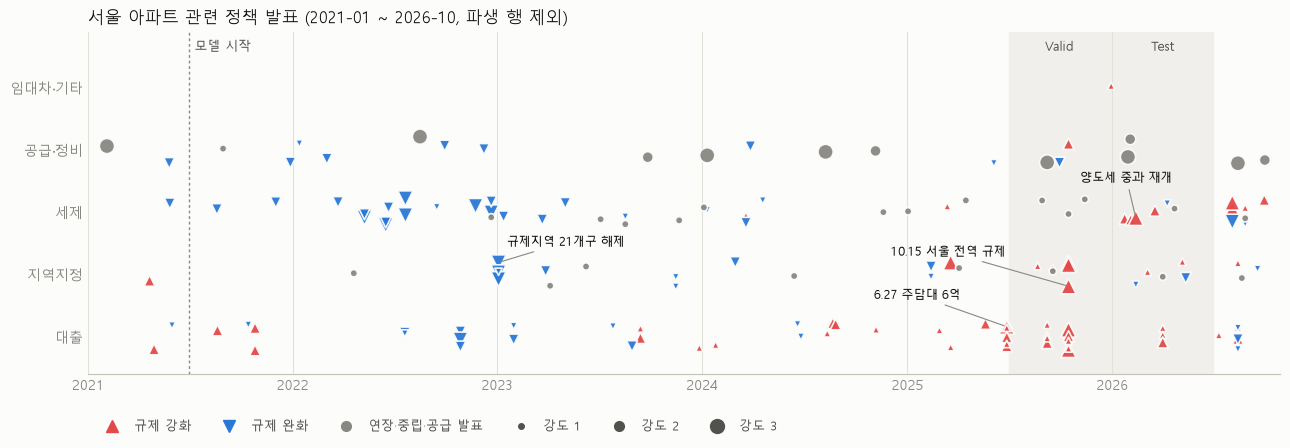

row,대출,지역지정,세제,공급·정비,임대차·기타
announce_date,,,,,
2021,6,1,3,4,0
2022,5,1,13,5,0
2023,7,10,7,1,0
2024,7,2,6,4,0
2025,21,10,6,4,1
2026,9,8,13,4,0


In [6]:
# ============================================================
# 정책 타임라인 (2021 ~ 2026-10)
# - 가로: 발표일, 세로: 정책 영역
# - 색·모양: 규제 강화(빨강 ▲) / 규제 완화(파랑 ▼) / 연장·중립·공급발표(회색 ●)
# - 크기: 강도(1~3). 회색 띠는 V1과 같은 Valid(2025-H2)·Test(2026-H1) 구간
# ============================================================

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BAND = "#f0efec"
COLOR_TIGHT = "#e34948"
COLOR_EASE = "#2a78d6"

GROUP_ORDER = ["대출", "지역지정", "세제", "공급·정비", "임대차·기타"]

tl = events[
    events["event_role"].ne("파생")
    & events["announce_date"].between("2021-01-01", LATEST_DATE)
].copy()

tl["row"] = tl["policy_group"].replace({"임대차": "임대차·기타", "기타": "임대차·기타"})
tl["kind"] = np.select(
    [
        tl["policy_category"].eq("공급대책"),
        tl["direction"].eq("강화"),
        tl["direction"].eq("완화"),
    ],
    ["neutral", "tight", "ease"],
    default="neutral",
)

STYLE = {
    "tight": dict(color=COLOR_TIGHT, marker="^"),
    "ease": dict(color=COLOR_EASE, marker="v"),
    "neutral": dict(color=MUTED, marker="o"),
}

rng = np.random.default_rng(0)
tl["y"] = tl["row"].map({g: i for i, g in enumerate(GROUP_ORDER)}) + rng.uniform(-0.22, 0.22, len(tl))
tl["size"] = tl["intensity"].map({1: 28, 2: 64, 3: 120})

fig, ax = plt.subplots(figsize=(13, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

for start, end, label in [
    ("2025-07-01", "2025-12-31", "Valid"),
    ("2026-01-01", "2026-06-30", "Test"),
]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=BAND, zorder=0)
    ax.text(pd.Timestamp(start) + pd.Timedelta(days=90), len(GROUP_ORDER) - 0.45, label,
            ha="center", va="bottom", color=INK_2, fontsize=9)

ax.axvline(pd.Timestamp("2021-07-01"), color=MUTED, lw=1, ls=(0, (2, 2)), zorder=1)
ax.text(pd.Timestamp("2021-07-01"), len(GROUP_ORDER) - 0.45, " 모델 시작", color=INK_2, fontsize=9, va="bottom")

for kind, st in STYLE.items():
    d = tl[tl["kind"] == kind]
    ax.scatter(d["announce_date"], d["y"], s=d["size"], c=st["color"], marker=st["marker"],
               edgecolors=SURFACE, linewidths=1.2, alpha=0.95, zorder=3)

# 강도 3 중 주요 이벤트만 직접 라벨
LABELS = {
    "P074": ("규제지역 21개구 해제", (6, 12)),
    "P130": ("6.27 주담대 6억", (-96, 20)),
    "P156": ("10.15 서울 전역 규제", (-128, 22)),
    "P168": ("양도세 중과 재개", (-40, 26)),
}
for eid, (text, offset) in LABELS.items():
    r = tl.loc[tl["event_id"] == eid].iloc[0]
    ax.annotate(text, (r["announce_date"], r["y"]), xytext=offset, textcoords="offset points",
                fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

ax.set_yticks(range(len(GROUP_ORDER)), GROUP_ORDER, color=INK_2)
ax.set_ylim(-0.6, len(GROUP_ORDER) - 0.1)
ax.set_xlim(pd.Timestamp("2021-01-01"), LATEST_DATE + pd.Timedelta(days=20))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.tick_params(colors=MUTED, length=0)
ax.grid(axis="x", color=GRID, lw=0.8)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")

legend_items = [
    Line2D([], [], ls="", marker="^", color=COLOR_TIGHT, ms=8, label="규제 강화"),
    Line2D([], [], ls="", marker="v", color=COLOR_EASE, ms=8, label="규제 완화"),
    Line2D([], [], ls="", marker="o", color=MUTED, ms=7, label="연장·중립·공급 발표"),
    Line2D([], [], ls="", marker="o", color=INK_2, ms=4, label="강도 1"),
    Line2D([], [], ls="", marker="o", color=INK_2, ms=7, label="강도 2"),
    Line2D([], [], ls="", marker="o", color=INK_2, ms=10, label="강도 3"),
]
ax.legend(handles=legend_items, loc="upper left", bbox_to_anchor=(0, -0.1), ncol=6,
          frameon=False, fontsize=9, labelcolor=INK_2)
ax.set_title("서울 아파트 관련 정책 발표 (2021-01 ~ 2026-10, 파생 행 제외)", loc="left", color=INK, fontsize=12)

plt.tight_layout()
plt.show()

display(
    tl.pivot_table(index=tl["announce_date"].dt.year, columns="row", values="event_id",
                   aggfunc="count", fill_value=0)[GROUP_ORDER]
)

## 2. 상태 규칙 정의

지역 지정(투기과열·조정대상·투기지역·토허·분상제)은 구별 구간표에서 가져오고,
대출·세제 상태는 아래 이벤트 ID로 규칙을 만든다. ID가 바뀌면 정책명 검사에서 멈추도록 했다.

| 상태 | 규칙 |
|---|---|
| `DSR단계` | P034(1단계) → P043(2단계) → P044(3단계) |
| `스트레스DSR단계` | P098 → P114 → P128 |
| `LTV_무주택` | 투기과열: 40% → 50%(P064, 2022-12-01) → 40%(P141, 2025-09-08) / 비규제 70% |
| `고가주택_주담대금지` | 투기과열 & P011(2019-12-17) 시행 ~ P065(2022-12-01) 해제 전 — 15억 초과 주담대 금지 |
| `주담대_6억상한` | P130(2025-06-28) 이후, 수도권 전체 |
| `주담대_가격차등` | P150·P151(2025-10-16) 이후: 15억 이하 6억 / 15~25억 4억 / 25억 초과 2억 |
| `양도세중과_적용` | 조정대상지역 & 중과 유예(P051·P069·P101·P119: 2022-05-10 ~ 2026-05-09) 밖 |

**방향 부호 주의:** 규제 이벤트의 `완화`는 대출·거래 제한이 풀린다는 뜻(가격 상승 압력)이고,
공급대책의 `완화`는 공급으로 가격을 누른다는 뜻이라 의미가 반대다.
그래서 공급대책은 규제 순강도 합계에서 빼고 `공급_강도합`으로 따로 둔다.

In [7]:
# ============================================================
# 규칙 이벤트 ID 고정 및 정책명 검사
# ============================================================

ev_idx = events.set_index("event_id")

RULE_EVENTS = {
    "P034": "DSR 1단계",
    "P043": "DSR 2단계",
    "P044": "DSR 3단계",
    "P098": "스트레스 DSR 1단계",
    "P114": "스트레스 DSR 2단계",
    "P128": "스트레스 DSR 3단계",
    "P011": "15억 초과",
    "P065": "15억 초과",
    "P064": "LTV 50%",
    "P141": "LTV 50%→40%",
    "P130": "6억",
    "P150": "15억 초과~25억",
    "P151": "25억 초과",
    "P051": "중과 한시 배제",
    "P069": "연장(1차)",
    "P101": "연장(2차)",
    "P119": "연장(3차",
    "P168": "유예 종료",
}

for eid, keyword in RULE_EVENTS.items():
    name = ev_idx.loc[eid, "policy_name"]
    assert keyword in name, (eid, name)

display(ev_idx.loc[list(RULE_EVENTS), ["announce_date", "effective_date", "end_date", "policy_name"]])

,announce_date,effective_date,end_date,policy_name
event_id,,,,
P034,2021-04-29,2021-07-01,NaT,차주단위 DSR 1단계: 규제지역 시가 6억 초과 주택 주담대·1억 초과 신용대출
P043,2021-10-26,2022-01-01,NaT,차주단위 DSR 2단계 조기시행(총대출 2억 초과)·카드론 DSR 포함·2금융권 D...
P044,2021-10-26,2022-07-01,NaT,차주단위 DSR 3단계(총대출 1억 초과)
P098,2023-12-27,2024-02-26,NaT,스트레스 DSR 1단계: 은행권 주담대(스트레스 금리 25%)
P114,2024-08-21,2024-09-01,NaT,"스트레스 DSR 2단계: 은행 주담대·신용대출·2금융권 주담대 50%, 수도권 은행..."
P128,2025-05-20,2025-07-01,NaT,스트레스 DSR 3단계: 전 업권 사실상 모든 가계대출 100%(1.5%p)
P011,2019-12-16,2019-12-17,NaT,투기지역·투기과열지구 시가 15억 초과 아파트 주택구입목적 주담대 금지
P065,2022-10-27,2022-12-01,NaT,투기·투기과열지구 시가 15억 초과 아파트 주담대 허용
P064,2022-10-27,2022-12-01,NaT,규제지역 무주택·1주택자 LTV 50% 일원화


In [8]:
# ============================================================
# 상태 계산 함수
# - dates 시점에 이벤트가 '시행 중'인지: 발표일 < dates 그리고 시행일 <= dates
# - known_ids: 누수 검증에서 기준 시점 이후 발표된 이벤트를 지우고 다시 계산할 때 사용
# ============================================================

def rule_active(eid, dates, known_ids=None):
    if known_ids is not None and eid not in known_ids:
        return pd.Series(False, index=dates.index)

    r = ev_idx.loc[eid]
    return (dates > r["announce_date"]) & (dates >= r["effective_date"])


def known_zones(zone_table, known_ids=None):
    # 누수 검증용: 기준 시점에 발표되지 않은 지정은 지우고, 발표되지 않은 해제는 아직 유지 중으로 본다.
    if known_ids is None:
        return zone_table

    z = zone_table[zone_table["start_event_id"].isin(known_ids)].copy()
    z.loc[~z["end_event_id"].isin(known_ids), "end_date"] = pd.NaT
    return z


def zone_flags(keys, gu_col, date_col, zone_table=zone_gu, known_ids=None):
    # 구별 구간표에서 dates 시점에 유효한 지정을 0/1 열로 펼친다.
    columns = sorted(zone_table["designation"].unique())
    zone_table = known_zones(zone_table, known_ids)

    m = (
        keys[[gu_col, date_col]]
        .reset_index()
        .merge(zone_table, left_on=gu_col, right_on="자치구", how="inner")
    )

    active = (
        (m["start_announce_date"] < m[date_col])
        & (m["start_date"] <= m[date_col])
        & (m["end_date"].isna() | (m["end_date"] >= m[date_col]))
    )

    flags = (
        m[active]
        .assign(v=1)
        .pivot_table(index="index", columns="designation", values="v", aggfunc="max")
        .reindex(index=keys.index, columns=columns)
        .fillna(0)
        .astype(int)
    )

    return flags


def policy_state(keys, gu_col, date_col, known_ids=None):
    # 구·시점별 지역지정 + 대출·세제 상태
    z = zone_flags(keys, gu_col, date_col, known_ids=known_ids)
    d = keys[date_col]
    out = pd.DataFrame(index=keys.index)

    out["투기과열지구"] = z["투기과열지구"]
    out["조정대상지역"] = z["조정대상지역"]
    out["투기지역"] = z["투기지역"]
    out["분양가상한제"] = z["분양가상한제"]
    out["분양가상한제_일부동"] = z["분양가상한제_일부동"]
    out["토허_구전역"] = z["토허구역_구전역"]
    out["토허_일부동"] = z["토허구역_일부동"]

    act = lambda eid: rule_active(eid, d, known_ids)

    out["DSR단계"] = act("P034").astype(int) + act("P043") + act("P044")
    out["스트레스DSR단계"] = act("P098").astype(int) + act("P114") + act("P128")

    regulated = out["투기과열지구"].eq(1)
    ltv_regulated = np.select([act("P141"), act("P064")], [40, 50], default=40)
    out["LTV_무주택"] = np.where(regulated, ltv_regulated, 70)

    out["고가주택_주담대금지"] = (regulated & act("P011") & ~act("P065")).astype(int)
    out["주담대_6억상한"] = act("P130").astype(int)
    out["주담대_가격차등"] = (act("P150") & act("P151")).astype(int)

    grace = act("P051") | act("P069") | act("P101") | act("P119")
    grace_end = pd.Timestamp("2026-05-09")  # P119 종료일, P168로 재연장 없음 확정
    in_grace = grace & (d <= grace_end)
    out["양도세중과_적용"] = (out["조정대상지역"].eq(1) & ~in_grace).astype(int)

    return out

## 3. 구×월 Feature (`policy_v2.parquet`)

- **상태:** 기준월 1일 시점의 지역지정·대출·세제 상태 (위 규칙)
- **이벤트 집계:** 기준월 직전 3·6개월(m-3 ~ m-1월)에 **발표된** 정책. 해당 구가 대상이거나 `전체` 대상인 이벤트만 센다.
  - `정책_강화수/완화수`: 규제 이벤트 건수 (공급대책 제외)
  - `정책_순강도`: Σ(강화 +1 / 완화 −1 × 강도), 영역별(`대출`·`지역지정`·`세제`)도 따로
  - `공급_강도합`: 공급대책 발표 강도 합
  - `경과개월_최근강화/완화`: 강도 2 이상 규제 강화/완화 발표 후 지난 개월 수
- 한 대책을 여러 행으로 나눠 기록한 경우(예: 1.3 대책의 투기과열·조정·투기지역·분상제 해제 4행)
  **같은 발표일·같은 영역·같은 방향** 묶음에서는 강도가 가장 큰 1건만 센다.
- 미시행·계류 법안과 신호(발언·예고)도 기대에 영향을 주므로 발표 집계에 포함한다. 상태값에는 넣지 않는다.

In [9]:
# ============================================================
# 이벤트를 (이벤트, 자치구) 단위로 펼치기
# - 파생 행 제외, 대상 구가 없는 행(서울 미적용)은 제외
# ============================================================

def explode_events(ev):
    e = ev[ev["event_role"].ne("파생") & ev["target_gu"].notna()].copy()

    e["자치구"] = e["target_gu"].map(
        lambda s: ALL_GU if s == "전체" else s.split(";")
    )
    e = e.explode("자치구")

    e["known_month"] = e["announce_date"].fillna(e["effective_date"]).dt.to_period("M")
    e["is_supply"] = e["policy_category"].eq("공급대책")
    e["sign"] = e["direction"].map({"강화": 1, "완화": -1}).fillna(0).astype(int)
    e["signed"] = np.where(e["is_supply"], 0, e["sign"] * e["intensity"])

    return e


ev_gu_all = explode_events(events)
print("(이벤트, 구) 행:", len(ev_gu_all))
print("발표월 범위:", ev_gu_all["known_month"].min(), "~", ev_gu_all["known_month"].max())

(이벤트, 구) 행: 4008
발표월 범위: 2016-11 ~ 2026-09


In [10]:
# ============================================================
# 구×월 이벤트 집계 함수
# - 구별 월 패널(최초 발표월 ~ 2026-06)을 만들고 rolling 후 shift(1)
#   → m월 값은 m-3(또는 m-6) ~ m-1월 발표분만 포함한다.
# ============================================================

def dedupe_bundles(ev_gu):
    # 같은 날 같은 영역·같은 방향으로 발표된 행(한 대책을 여러 행으로 나눈 경우)은 강도가 가장 큰 1건만 센다.
    key = ["자치구", "known_date", "policy_group", "is_supply", "sign"]
    return (
        ev_gu.assign(known_date=ev_gu["announce_date"].fillna(ev_gu["effective_date"]))
        .sort_values(["intensity", "event_id"], ascending=[False, True])
        .drop_duplicates(key)
    )


def event_aggregates(ev_gu, months_needed):
    ev_gu = dedupe_bundles(ev_gu)
    reg = ev_gu[~ev_gu["is_supply"]]
    sup = ev_gu[ev_gu["is_supply"]]

    first = min(ev_gu["known_month"].min(), months_needed.min() - 12)
    months = pd.period_range(first, months_needed.max(), freq="M")
    panel_idx = pd.MultiIndex.from_product([ALL_GU, months], names=["자치구", "month"])

    def monthly(df, value):
        return (
            df.groupby(["자치구", "known_month"])[value].sum()
            .rename_axis(["자치구", "month"])
            .reindex(panel_idx, fill_value=0)
        )

    base = pd.DataFrame({
        "강화수": monthly(reg.assign(v=reg["sign"].eq(1).astype(int)), "v"),
        "완화수": monthly(reg.assign(v=reg["sign"].eq(-1).astype(int)), "v"),
        "순강도": monthly(reg, "signed"),
        "대출": monthly(reg[reg["policy_group"].eq("대출")], "signed"),
        "지역지정": monthly(reg[reg["policy_group"].eq("지역지정")], "signed"),
        "세제": monthly(reg[reg["policy_group"].eq("세제")], "signed"),
        "공급": monthly(sup, "intensity"),
        "강화_major": monthly(reg.assign(v=(reg["sign"].eq(1) & reg["intensity"].ge(2)).astype(int)), "v"),
        "완화_major": monthly(reg.assign(v=(reg["sign"].eq(-1) & reg["intensity"].ge(2)).astype(int)), "v"),
    })

    g = base.groupby(level="자치구", group_keys=False)

    def past(col, w):
        return g[col].apply(lambda s: s.rolling(w, min_periods=1).sum().shift(1))

    out = pd.DataFrame(index=base.index)
    out["정책_강화수_3m"] = past("강화수", 3)
    out["정책_완화수_3m"] = past("완화수", 3)
    out["정책_순강도_3m"] = past("순강도", 3)
    out["정책_강화수_6m"] = past("강화수", 6)
    out["정책_완화수_6m"] = past("완화수", 6)
    out["정책_순강도_6m"] = past("순강도", 6)
    out["대출_순강도_6m"] = past("대출", 6)
    out["지역지정_순강도_6m"] = past("지역지정", 6)
    out["세제_순강도_6m"] = past("세제", 6)
    out["공급_강도합_6m"] = past("공급", 6)

    month_no = pd.Series(
        [p.ordinal for p in base.index.get_level_values("month")], index=base.index
    )

    for col, name in [("강화_major", "경과개월_최근강화"), ("완화_major", "경과개월_최근완화")]:
        last = month_no.where(base[col] > 0)
        last = last.groupby(level="자치구").transform(lambda s: s.ffill().shift(1))
        out[name] = month_no - last

    out = out.reset_index()
    return out[out["month"].isin(months_needed)]

In [11]:
# ============================================================
# 구×월 Feature 생성
# ============================================================

def build_region_month(ev, grid, known_ids=None):
    g = grid.copy()
    g["month"] = pd.PeriodIndex(g["기준월"], freq="M")
    g["cutoff"] = g["month"].dt.to_timestamp()

    state = policy_state(g, "자치구", "cutoff", known_ids=known_ids)
    agg = event_aggregates(explode_events(ev), pd.PeriodIndex(g["month"].unique()))

    return (
        pd.concat([g, state], axis=1)
        .merge(agg, on=["자치구", "month"], how="left")
    )


policy_rm = build_region_month(events, region_month)

STATE_FEATURES = [
    "투기과열지구", "조정대상지역", "투기지역", "분양가상한제", "분양가상한제_일부동",
    "토허_구전역", "토허_일부동", "DSR단계", "스트레스DSR단계", "LTV_무주택",
    "고가주택_주담대금지", "주담대_6억상한", "주담대_가격차등", "양도세중과_적용",
]

EVENT_FEATURES = [
    "정책_강화수_3m", "정책_완화수_3m", "정책_순강도_3m",
    "정책_강화수_6m", "정책_완화수_6m", "정책_순강도_6m",
    "대출_순강도_6m", "지역지정_순강도_6m", "세제_순강도_6m",
    "공급_강도합_6m", "경과개월_최근강화", "경과개월_최근완화",
]

POLICY_RM_FEATURES = STATE_FEATURES + EVENT_FEATURES

print(policy_rm.shape)
print("Feature 수:", len(POLICY_RM_FEATURES))
display(policy_rm[["기준월", "자치구"] + POLICY_RM_FEATURES].head())

(1500, 31)
Feature 수: 26


,기준월,자치구,투기과열지구,조정대상지역,투기지역,분양가상한제,분양가상한제_일부동,토허_구전역,토허_일부동,DSR단계,...,정책_순강도_3m,정책_강화수_6m,정책_완화수_6m,정책_순강도_6m,대출_순강도_6m,지역지정_순강도_6m,세제_순강도_6m,공급_강도합_6m,경과개월_최근강화,경과개월_최근완화
0,2021-07,강남구,1,1,1,1,0,0,1,1,...,-1.0,2.0,3.0,-1.0,1.0,2.0,-2.0,3.0,3.0,2.0
1,2021-08,강남구,1,1,1,1,0,0,1,1,...,-5.0,2.0,3.0,-1.0,1.0,2.0,-2.0,3.0,4.0,3.0
2,2021-09,강남구,1,1,1,1,0,0,1,1,...,0.0,3.0,4.0,-1.0,3.0,2.0,-4.0,1.0,1.0,1.0
3,2021-10,강남구,1,1,1,1,0,0,1,1,...,0.0,3.0,4.0,-1.0,3.0,2.0,-4.0,1.0,2.0,2.0
4,2021-11,강남구,1,1,1,1,0,0,1,1,...,1.0,2.0,5.0,-4.0,2.0,0.0,-4.0,1.0,1.0,3.0


In [12]:
# ============================================================
# 상태 변화 점검: 서울 전체 상태가 바뀐 달만 출력
# - 2023-02(21개구 해제), 2025-11(서울 전역 재지정) 등이 보여야 한다.
# ============================================================

seoul_state = (
    policy_rm
    .groupby("기준월")[STATE_FEATURES]
    .sum()
)

changed = seoul_state.ne(seoul_state.shift()).any(axis=1)
display(seoul_state[changed])

,투기과열지구,조정대상지역,투기지역,분양가상한제,분양가상한제_일부동,토허_구전역,토허_일부동,DSR단계,스트레스DSR단계,LTV_무주택,고가주택_주담대금지,주담대_6억상한,주담대_가격차등,양도세중과_적용
기준월,,,,,,,,,,,,,,
2021-07,25,25,15,13,5,0,6,25,0,1000,25,0,0,25
2022-01,25,25,15,13,5,0,6,50,0,1000,25,0,0,25
2022-06,25,25,15,13,5,0,6,50,0,1000,25,0,0,0
2022-07,25,25,15,13,5,0,6,75,0,1000,25,0,0,0
2022-12,25,25,15,13,5,0,6,75,0,1250,0,0,0,0
2023-02,4,4,4,4,0,0,6,75,0,1670,0,0,0,0
2024-03,4,4,4,4,0,0,6,75,25,1670,0,0,0,0
2024-09,4,4,4,4,0,0,6,75,50,1670,0,0,0,0
2025-04,4,4,4,4,0,4,6,75,50,1670,0,0,0,0


In [13]:
# ============================================================
# 구별 이벤트 집계 예시: 강남구 vs 노원구
# - 강남구는 토허·분상제 등 구 단위 이벤트가 더해져 값이 다르다.
# ============================================================

display(
    policy_rm[policy_rm["자치구"].isin(["강남구", "노원구"])]
    .pivot_table(index="기준월", columns="자치구",
                 values=["정책_순강도_6m", "지역지정_순강도_6m", "경과개월_최근강화"])
    .loc[["2023-01", "2023-02", "2025-03", "2025-04", "2025-10", "2025-11", "2026-06"]]
)

경과개월_최근강화       정책_순강도_6m       지역지정_순강도_6m     
자치구           강남구   노원구       강남구   노원구         강남구  노원구
기준월                                                     
2023-01      15.0  15.0     -19.0 -19.0         0.0  0.0
2023-02      16.0  16.0     -19.0 -21.0        -1.0 -3.0
2025-03       7.0   7.0       0.0   2.0        -2.0  0.0
2025-04       1.0   8.0       5.0   3.0         1.0  0.0
2025-10       1.0   4.0       5.0   4.0         1.0  1.0
2025-11       1.0   1.0      13.0  12.0         4.0  4.0
2026-06       2.0   2.0       9.0   8.0        -2.0 -3.0

## 4. 거래 단위 Feature

구×월 표로는 표현할 수 없는 두 가지를 거래별로 붙인다.

1. **토지거래허가구역의 동·단지 범위:** 잠실·삼성·청담·대치(2025-02-13 이후 재건축 14곳만),
   압구정 아파트지구, 목동 신시가지 1~14단지, 여의도 16개 단지는 같은 구 안에서도 단지마다 다르다.
2. **가격 조건이 있는 대출 규제:** 15억 초과 주담대 금지(2019-12 ~ 2022-11), 6억 상한, 6·4·2억 차등.
   가격 구간은 **거래 전에 알 수 있는 예상가격**으로 판단한다.

In [14]:
# ============================================================
# 거래 전 예상가격
# - 실거래 신고기한(계약 후 30일)을 고려해 계약일 30일 전까지 공개됐을 거래만 쓴다.
#   창: [계약일 - 395일, 계약일 - 30일)
# - 우선순위: ① 같은 단지 → ② 같은 법정동·같은 면적대 → ③ 같은 구의 2개월 전 월 중위
#   ③ m-2월 거래는 m-1월 말까지 모두 신고되므로 m월 계약 시점에 공개된 값이다.
# ============================================================

PYEONG = 3.3058
LAG_DAYS, WINDOW_DAYS = 30, 365

t = trade.copy()
t["평당가"] = t["평당가"].astype(float)
t["면적대"] = pd.cut(t["전용면적"].astype(float), [0, 60, 85, 135, np.inf],
                    labels=["≤60", "60~85", "85~135", ">135"])
t["day"] = t["계약일자"].to_numpy().astype("datetime64[D]").astype(np.int64)


def window_median(df, keys):
    # 각 거래에 대해 같은 key 거래 중 [d-395, d-30) 구간의 평당가 중위수와 건수
    day_all = df["day"].to_numpy()
    val_all = df["평당가"].to_numpy()
    med = np.full(len(df), np.nan)
    cnt = np.zeros(len(df), dtype=int)

    for idx in df.groupby(keys, observed=True).indices.values():
        idx = idx[np.argsort(day_all[idx], kind="stable")]
        day, val = day_all[idx], val_all[idx]
        lo = np.searchsorted(day, day - (WINDOW_DAYS + LAG_DAYS), side="left")
        hi = np.searchsorted(day, day - LAG_DAYS, side="left")

        for j in np.flatnonzero(hi > lo):
            med[idx[j]] = np.median(val[lo[j]:hi[j]])
            cnt[idx[j]] = hi[j] - lo[j]

    return med, cnt


t["단지_중위평당가"], t["단지_거래수"] = window_median(t, ["단지일련번호"])
t["동면적_중위평당가"], t["동면적_거래수"] = window_median(t, ["시군구명", "법정동", "면적대"])

gu_month = (
    t.groupby(["시군구명", t["계약일자"].dt.to_period("M").rename("month")])["평당가"]
    .median()
    .rename("구_2개월전_중위평당가")
    .reset_index()
)
gu_month["month"] = gu_month["month"] + 2  # m-2월 값을 m월에 붙인다

t["month"] = t["계약일자"].dt.to_period("M")
t = t.merge(gu_month, on=["시군구명", "month"], how="left")
assert len(t) == len(trade) and t["transaction_id"].equals(trade["transaction_id"])

source = np.select(
    [t["단지_거래수"] > 0, t["동면적_거래수"] > 0, t["구_2개월전_중위평당가"].notna()],
    ["단지", "동·면적대", "구"],
    default="없음",
)
price_per_py = np.select(
    [source == "단지", source == "동·면적대", source == "구"],
    [t["단지_중위평당가"], t["동면적_중위평당가"], t["구_2개월전_중위평당가"]],
    default=np.nan,
)

t["예상가격_만원"] = price_per_py * t["전용면적"].astype(float) / PYEONG
t["예상가격_출처"] = source

display(
    pd.crosstab(t["계약일자"].dt.year, t["예상가격_출처"], normalize="index").round(3)
)

예상가격_출처,구,단지,동·면적대,없음
계약일자,,,,
2021,0.006,0.483,0.195,0.316
2022,0.004,0.828,0.169,0.000
2023,0.004,0.898,0.099,0.000
2024,0.001,0.955,0.044,0.000
2025,0.002,0.961,0.038,0.000
2026,0.001,0.960,0.039,0.000


In [15]:
# ============================================================
# 예상가격 누수 검증
# - 출처별 표본을 원본에서 직접 다시 계산해 같은 값인지 확인한다.
#   (계약일 30일 전 이후 거래·당일·미래 거래 미포함)
# ============================================================

lo_gap, hi_gap = pd.Timedelta(days=WINDOW_DAYS + LAG_DAYS), pd.Timedelta(days=LAG_DAYS)

for _, r in t[t["예상가격_출처"] == "단지"].sample(200, random_state=42).iterrows():
    prior = t[
        (t["단지일련번호"] == r["단지일련번호"])
        & (t["계약일자"] >= r["계약일자"] - lo_gap)
        & (t["계약일자"] < r["계약일자"] - hi_gap)
    ]
    assert len(prior) == r["단지_거래수"]
    assert np.isclose(prior["평당가"].median(), r["단지_중위평당가"])

for _, r in t[t["예상가격_출처"] == "동·면적대"].sample(100, random_state=42).iterrows():
    prior = t[
        (t["시군구명"] == r["시군구명"]) & (t["법정동"] == r["법정동"]) & (t["면적대"] == r["면적대"])
        & (t["계약일자"] >= r["계약일자"] - lo_gap)
        & (t["계약일자"] < r["계약일자"] - hi_gap)
    ]
    assert len(prior) == r["동면적_거래수"]
    assert np.isclose(prior["평당가"].median(), r["동면적_중위평당가"])

for _, r in t[t["예상가격_출처"] == "구"].sample(100, random_state=42).iterrows():
    prior = t[(t["시군구명"] == r["시군구명"]) & (t["month"] == r["month"] - 2)]
    assert np.isclose(prior["평당가"].median(), r["구_2개월전_중위평당가"])

print("✅ 예상가격은 계약일 30일 전까지 공개된 거래만 사용")

✅ 예상가격은 계약일 30일 전까지 공개된 거래만 사용


In [16]:
# ============================================================
# 예상가격 정확도 (검증용)
# - 실제 거래금액은 여기서만 읽고 Feature 계산에는 쓰지 않는다.
# ============================================================

actual = (
    pd.read_parquet(PROCESSED_DIR / "df_fe_base.parquet", columns=["transaction_id", "거래금액"])
    .set_index("transaction_id")["거래금액"]
    .astype(float)
)

acc = t[["transaction_id", "계약일자", "예상가격_출처", "예상가격_만원"]].copy()
acc["실제"] = acc["transaction_id"].map(actual)
acc["예상/실제"] = acc["예상가격_만원"] / acc["실제"]

display(
    acc.groupby("예상가격_출처")["예상/실제"]
    .describe(percentiles=[0.05, 0.5, 0.95])
    .round(3)
)

# 15억 초과 주담대 금지 시기(~2022-11-30) 판정 정확도
era = acc[acc["계약일자"] < "2022-12-01"].dropna(subset=["예상가격_만원"])
display(
    pd.crosstab(era["예상가격_만원"] > 150000, era["실제"] > 150000,
                rownames=["예상 >15억"], colnames=["실제 >15억"])
)

,count,mean,std,min,5%,50%,95%,max
예상가격_출처,,,,,,,,
구,478.0,1.477,0.619,0.424,0.779,1.257,2.685,5.039
단지,213308.0,0.977,0.148,0.340,0.769,0.965,1.243,2.796
동·면적대,15432.0,1.281,0.547,0.242,0.669,1.153,2.322,6.778
없음,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


실제 >15억,False,True
예상 >15억,,
False,17532,366
True,900,3448


In [17]:
# ============================================================
# 토지거래허가구역 — 동·단지 단위
# - 아파트 관련 구간만 사용: 재개발 후보지·모아타운(비아파트·저층주거지)은 제외
# - coverage=동전역/아파트만 → 동 전체 적용
# - coverage=일부 → 아래 단지명 규칙으로 판정. 규칙이 없는 동(성수 전략정비구역, 용산 정비창 인근)은
#   단지 판정을 하지 않고 '동 노출'로만 기록한다.
# ============================================================

apt_dong = zone_dong[
    zone_dong["designation"].eq("토지거래허가구역")
    & ~zone_dong["target_detail"].str.contains("비아파트|저층주거지", na=False)
].copy()

assert apt_dong["start_event_id"].notna().all()  # 누수 검증에 쓰도록 모든 구간이 발표 이벤트와 연결

print("아파트 관련 동 구간:", len(apt_dong))
display(apt_dong[["자치구", "법정동", "coverage", "start_date", "end_date"]])

YEOUIDO_16 = [
    "시범", "삼부", "한양", "광장", "광장(1,2동)", "공작", "수정", "서울",
    "진주", "순복음(초원)", "목화", "장미", "화랑", "대교", "삼익", "은하", "미성",
]

PARTIAL_COMPLEX_RULES = [
    # 자치구, 법정동, 구간 시작일, 단지명 정규식, 근거
    ("강남구", "압구정동", "2021-04-27", r".*", "압구정 아파트지구 24개 단지 전부"),
    ("양천구", "목동", "2021-04-27", r"^목동신시가지\d+$", "목동 신시가지 1~7단지"),
    ("양천구", "신정동", "2021-04-27", r"^목동신시가지\d+$", "목동 신시가지 8~14단지"),
    ("영등포구", "여의도동", "2021-04-27",
     "^(" + "|".join(map(re.escape, YEOUIDO_16)) + ")$",
     "여의도 아파트지구 등 16개 단지(목록 일부는 단지명으로 추정)"),
    ("강남구", "대치동", "2025-02-13",
     r"^(은마|한보미도맨션[12]|개포우성[12]|선경[12]차.*|쌍용대치.*|대치우성.*)$", "재건축 14곳"),
    ("강남구", "청담동", "2025-02-13", r"^(현대아파트\(75-1\)|진흥아파트)$", "재건축 14곳"),
    ("강남구", "삼성동", "2025-02-13", r"^진흥아파트$", "재건축 14곳"),
    ("송파구", "잠실동", "2025-02-13",
     r"^(주공아파트 5단지|우성아파트|우성4차|아시아선수촌아파트)$", "재건축 14곳"),
]

rules = pd.DataFrame(
    PARTIAL_COMPLEX_RULES,
    columns=["자치구", "법정동", "start_date", "pattern", "근거"],
)
rules["start_date"] = pd.to_datetime(rules["start_date"])

check = rules.merge(apt_dong, on=["자치구", "법정동", "start_date"], how="left", indicator=True)
assert check["_merge"].eq("both").all(), check
assert check["coverage"].eq("일부(구역·단지)").all()

apt_dong = apt_dong.merge(rules, on=["자치구", "법정동", "start_date"], how="left")

아파트 관련 동 구간: 24


,자치구,법정동,coverage,start_date,end_date
0,강남구,삼성동,동전역,2020-06-23,2023-11-15
1,강남구,삼성동,아파트만,2023-11-16,2025-02-12
2,강남구,삼성동,일부(구역·단지),2025-02-13,NaT
3,강남구,청담동,동전역,2020-06-23,2023-11-15
4,강남구,청담동,아파트만,2023-11-16,2025-02-12
5,강남구,청담동,일부(구역·단지),2025-02-13,NaT
6,강남구,대치동,동전역,2020-06-23,2023-11-15
7,강남구,대치동,아파트만,2023-11-16,2025-02-12
8,강남구,대치동,일부(구역·단지),2025-02-13,NaT
9,송파구,잠실동,동전역,2020-06-23,2023-11-15


In [18]:
# ============================================================
# 거래별 토허 판정
# ============================================================

def permit_zone_flags(tr, date_col="계약일자", known_ids=None):
    # 토허_동노출: 동·단지 단위 지정 구간이 걸린 동에 있는 거래 (구 전역 지정과 별개)
    # 토허_단지지정: 그 거래의 단지가 실제 지정 대상인지 (동전역·아파트만 또는 단지명 규칙 일치)
    m = (
        tr[["시군구명", "법정동", "단지명", date_col]]
        .reset_index()
        .merge(known_zones(apt_dong, known_ids), left_on=["시군구명", "법정동"],
               right_on=["자치구", "법정동"], how="inner")
    )

    active = (
        (m["start_announce_date"] < m[date_col])
        & (m["start_date"] <= m[date_col])
        & (m["end_date"].isna() | (m["end_date"] >= m[date_col]))
    )
    m = m[active].copy()

    whole = m["coverage"].isin(["동전역", "아파트만"])
    by_name = m["pattern"].notna() & m.apply(
        lambda r: (
            isinstance(r["pattern"], str)
            and isinstance(r["단지명"], str)
            and re.match(r["pattern"], r["단지명"]) is not None
        ),
        axis=1,
    )

    m["단지적용"] = whole | by_name
    m["근거"] = np.where(whole, "동 " + m["coverage"], m["근거"])

    # 근거는 실제로 지정된 단지에만 붙인다 (웹 표시용)
    reason = (
        m[m["단지적용"]]
        .groupby("index")["근거"]
        .agg(lambda s: " / ".join(sorted(set(s.dropna()))))
    )

    out = pd.DataFrame(index=tr.index)
    out["토허_동노출"] = tr.index.isin(m["index"]).astype(int)
    out["토허_단지지정"] = tr.index.isin(m.loc[m["단지적용"], "index"]).astype(int)
    out["토허_근거"] = reason.reindex(tr.index)
    return out


permit = permit_zone_flags(t)

assert permit.loc[permit["토허_단지지정"].eq(0), "토허_근거"].isna().all()
assert permit.loc[permit["토허_단지지정"].eq(1), "토허_근거"].notna().all()

display(
    t.join(permit)
    .query("토허_단지지정 == 1")
    .groupby(["시군구명", "법정동", "토허_근거"])["단지명"]
    .agg(lambda s: ", ".join(sorted(s.unique())[:12]))
    .to_frame("판정된 단지(일부)")
)

판정된 단지(일부)
시군구명 법정동  토허_근거                                                                                 
강남구  대치동  동 동전역                                개포우성1, 개포우성2, 대우아이빌멤버스(891-26), 대우아이빌명문가(891-2...
          동 아파트만                               개포우성1, 개포우성2, 대우아이빌멤버스(891-26), 대우아이빌명문가(891-2...
          재건축 14곳                              개포우성1, 개포우성2, 대치우성아파트1동,2동,3동,5동,6동,7동, 선경1차(1...
     삼성동  동 동전역                                LG선릉에클라트(A), LG선릉에클라트(B), 골든카운티, 그라나다, 금호어울림, ...
          동 아파트만                               LG선릉에클라트(A), LG선릉에클라트(B), SM드림빌, 그라나다, 래미안라클래시...
          재건축 14곳                                                                          진흥아파트
     압구정동 압구정 아파트지구 24개 단지 전부                  미성1차, 미성2차, 신현대11차, 신현대12차, 신현대9차, 한양1차(영동한양),...
     청담동  동 동전역                                PH129, 대우로얄카운티3, 대우리츠카운티, 대우멤버스카운티Ⅱ, 더갤러리파크, 동...
          동 아파트만                               PH129, 대우로얄카운티2, 대우리츠카운티, 대우유로카운티, 더갤러리파크, 동양파...
          재건축 14곳                                                             진흥아파트, 현대아파트(75-1)
송파구  잠실동  동 동전역                                NS파인트리, 갤러리아팰리스, 레이크팰리스, 리센츠, 아시아선수촌아파트, 앙시레이크...
          동 아파트만                               NS파인트리, 갤러리아팰리스, 레이크팰리스, 리센츠, 신동아예지움, 아시아선수촌아파...
          재건축 14곳                                              아시아선수촌아파트, 우성4차, 우성아파트, 주공아파트 5단지
양천구  목동   목동 신시가지 1~7단지                        목동신시가지1, 목동신시가지2, 목동신시가지3, 목동신시가지4, 목동신시가지5, 목...
     신정동  목동 신시가지 8~14단지                       목동신시가지10, 목동신시가지11, 목동신시가지12, 목동신시가지13, 목동신시가지...
영등포구 여의도동 여의도 아파트지구 등 16개 단지(목록 일부는 단지명으로 추정)  공작, 광장, 광장(1,2동), 대교, 목화, 미성, 삼부, 삼익, 서울, 수정, ...

In [19]:
# ============================================================
# 주담대 최대한도 (무주택 실수요자, DSR 미반영)
# - 가격은 예상가격 기준. 단위: 만원
#   ~2022-11 투기과열: 9억 이하 40% + 9억 초과분 20%, 15억 초과 0
#   2022-12 ~      : 투기과열 50%(2025-09-08부터 40%), 비규제 70%
#   2025-06-28 ~   : 6억 상한 / 2025-10-16 ~ : 15억 이하 6억 · 15~25억 4억 · 25억 초과 2억
# ============================================================

def mortgage_limit(state, price):
    regulated = state["투기과열지구"].eq(1)
    ltv = state["LTV_무주택"] / 100
    split_era = regulated & state["고가주택_주담대금지"].eq(1)

    limit = np.where(
        split_era,
        np.where(price > 150000, 0, 0.4 * np.minimum(price, 90000) + 0.2 * np.maximum(price - 90000, 0)),
        ltv * price,
    )

    limit = np.where(state["주담대_6억상한"].eq(1), np.minimum(limit, 60000), limit)

    tier_cap = np.select([price <= 150000, price <= 250000], [60000, 40000], default=20000)
    limit = np.where(state["주담대_가격차등"].eq(1), np.minimum(limit, tier_cap), limit)

    return pd.Series(np.where(np.isnan(price), np.nan, limit), index=state.index)

In [20]:
# ============================================================
# 거래 단위 Feature 조립
# - 계약일 기준 상태(발표일 < 계약일, 시행일 <= 계약일)
# ============================================================

def build_trade(tr, known_ids=None):
    state = policy_state(tr, "시군구명", "계약일자", known_ids=known_ids)
    price = tr["예상가격_만원"].to_numpy(dtype=float)

    out = pd.DataFrame({"transaction_id": tr["transaction_id"]}, index=tr.index)
    out["투기과열지구_계약일"] = state["투기과열지구"]
    out["조정대상지역_계약일"] = state["조정대상지역"]
    out["토허_구전역_계약일"] = state["토허_구전역"]
    out["양도세중과_계약일"] = state["양도세중과_적용"]
    out["주담대_LTV_적용"] = state["LTV_무주택"]
    out["고가주택_주담대금지_해당"] = (
        state["고가주택_주담대금지"].eq(1) & (price > 150000)
    ).astype(int)
    out["주담대_최대한도_만원"] = mortgage_limit(state, price)
    out["주담대_한도비율"] = out["주담대_최대한도_만원"] / price

    permit = permit_zone_flags(tr, known_ids=known_ids)
    gu_wide = out["토허_구전역_계약일"].eq(1)

    out["토허_동노출"] = permit["토허_동노출"]
    out["토허_단지지정"] = (permit["토허_단지지정"].eq(1) | gu_wide).astype(int)  # 구 전역이면 모든 아파트
    out["토허_근거"] = np.where(gu_wide, "구 전역 아파트", permit["토허_근거"])
    out["토허_근거"] = out["토허_근거"].where(out["토허_단지지정"].eq(1))
    return out


policy_trade = build_trade(t)

policy_trade["예상가격_만원"] = t["예상가격_만원"]
policy_trade["예상가격_출처"] = t["예상가격_출처"]

TRADE_FEATURES = [
    "투기과열지구_계약일", "조정대상지역_계약일", "토허_구전역_계약일", "양도세중과_계약일",
    "토허_동노출", "토허_단지지정",
    "주담대_LTV_적용", "고가주택_주담대금지_해당", "주담대_최대한도_만원", "주담대_한도비율",
]
TRADE_DISPLAY = ["토허_근거", "예상가격_만원", "예상가격_출처"]

print(policy_trade.shape)
display(policy_trade[TRADE_FEATURES].describe().T.round(3))

(234302, 14)


,count,mean,std,min,25%,50%,75%,max
투기과열지구_계약일,234302.0,0.464,0.499,0.0,0.000,0.000,1.00,1.000
조정대상지역_계약일,234302.0,0.464,0.499,0.0,0.000,0.000,1.00,1.000
토허_구전역_계약일,234302.0,0.232,0.422,0.0,0.000,0.000,0.00,1.000
양도세중과_계약일,234302.0,0.141,0.348,0.0,0.000,0.000,0.00,1.000
토허_동노출,234302.0,0.081,0.273,0.0,0.000,0.000,0.00,1.000
토허_단지지정,234302.0,0.262,0.440,0.0,0.000,0.000,1.00,1.000
주담대_LTV_적용,234302.0,57.340,13.936,40.0,40.000,70.000,70.00,70.000
고가주택_주담대금지_해당,234302.0,0.019,0.135,0.0,0.000,0.000,0.00,1.000
주담대_최대한도_만원,229218.0,57562.017,41875.598,0.0,32429.091,48650.000,70781.42,1321557.615
주담대_한도비율,229218.0,0.547,0.178,0.0,0.400,0.691,0.70,0.700


In [21]:
# ============================================================
# 주담대 한도 점검: 시기·가격대별 평균 한도
# - 2025-11 이후 고가 구간 한도가 2~4억으로 떨어지는지 확인
# ============================================================

chk = t[["계약일자", "시군구명"]].join(policy_trade[["예상가격_만원", "주담대_최대한도_만원"]])
chk["가격대"] = pd.cut(chk["예상가격_만원"], [0, 90000, 150000, 250000, np.inf],
                    labels=["≤9억", "9~15억", "15~25억", ">25억"])
chk["반기"] = chk["계약일자"].dt.year.astype(str) + "H" + np.where(chk["계약일자"].dt.month <= 6, "1", "2")

display(
    chk.pivot_table(index="반기", columns="가격대", values="주담대_최대한도_만원",
                    aggfunc="mean", observed=False)
    .div(10000).round(2)
    .rename_axis(columns="평균 한도(억)")
)

평균 한도(억),≤9억,9~15억,15~25억,>25억
반기,,,,
2021H2,2.31,4.11,0.00,0.00
2022H1,1.91,4.11,0.00,0.00
2022H2,1.77,4.52,2.34,3.47
2023H1,4.13,7.66,11.02,18.29
2023H2,4.07,7.66,11.07,18.64
2024H1,4.22,7.72,11.10,18.40
2024H2,4.16,7.70,11.32,19.13
2025H1,4.27,7.85,11.60,18.99
2025H2,3.62,5.54,5.34,4.19


## 5. 누수 검증

1. **재계산 비교:** 각 시점에 대해 **그 시점 이전에 발표된 이벤트(지역 구간 포함)만 남기고 다시 계산한 값**이
   전체 데이터로 계산한 값과 같아야 한다. 다르면 미래에 발표된 정책이 Feature에 들어간 것이다.
2. **검증 자체 점검:** 발표 전에 시작하는 잘못된 구간을 일부러 넣었을 때 위 비교가 차이를 잡아내는지 확인한다.
3. **경계일 기대값:** 시행일 조건 오류는 1로 잡히지 않으므로(발표 후 시행이라 둘 다 같은 값),
   공식 출처로 확인한 경계일의 기대값을 직접 assert 한다.

In [22]:
# ============================================================
# 구×월: 60개 기준월 전부 재계산 비교
# ============================================================

leaks = []

for month in region_month["기준월"].unique():
    cutoff = pd.Period(month, freq="M").to_timestamp()
    known = events[events["announce_date"].fillna(events["effective_date"]) < cutoff]

    sub = build_region_month(
        known,
        region_month[region_month["기준월"] == month],
        known_ids=set(known["event_id"]),
    )
    full = policy_rm[policy_rm["기준월"] == month]

    diff = (
        sub.set_index("자치구")[POLICY_RM_FEATURES]
        .compare(full.set_index("자치구")[POLICY_RM_FEATURES])
    )
    if not diff.empty:
        leaks.append((month, diff))

print("누수 의심 기준월:", len(leaks))
assert not leaks, leaks[0]

print("✅ 구×월 Feature: 기준월 이후 발표 정책 미사용")

누수 의심 기준월: 0
✅ 구×월 Feature: 기준월 이후 발표 정책 미사용


In [23]:
# ============================================================
# 거래 단위: 계약일 200개 표본 재계산 비교
# ============================================================

dates = pd.Series(t["계약일자"].unique()).sample(200, random_state=7)

for d in dates:
    tr = t[t["계약일자"] == d]
    known_ids = set(events.loc[events["announce_date"].fillna(events["effective_date"]) < d, "event_id"])

    sub = build_trade(tr, known_ids=known_ids)[TRADE_FEATURES]
    full = build_trade(tr)[TRADE_FEATURES]

    pd.testing.assert_frame_equal(sub, full)

print("✅ 거래 단위 Feature: 계약일 이후 발표 정책 미사용 (지역 구간·토허 포함)")

✅ 거래 단위 Feature: 계약일 이후 발표 정책 미사용 (지역 구간·토허 포함)


In [24]:
# ============================================================
# 검증 자체 점검: 10.15 지정(발표 2025-10-15) 구간을 2025-09-25 시작으로 잘못 넣으면
# 2025-10 기준월 비교에서 차이가 나야 한다.
# ============================================================

bad_zone = zone_gu.copy()
bad_zone.loc[bad_zone["start_event_id"].eq("P156"), ["start_date", "start_announce_date"]] = pd.Timestamp("2025-09-25")

probe = region_month[region_month["기준월"] == "2025-10"].assign(cutoff=pd.Timestamp("2025-10-01"))
probe_known = set(events.loc[events["announce_date"].fillna(events["effective_date"]) < "2025-10-01", "event_id"])

full_bad = zone_flags(probe, "자치구", "cutoff", zone_table=bad_zone)
sub_bad = zone_flags(probe, "자치구", "cutoff", zone_table=bad_zone, known_ids=probe_known)

detected = full_bad.ne(sub_bad).sum()
print("잘못된 구간 주입 시 차이:", detected[detected > 0].to_dict())
assert detected["투기과열지구"] == 21

print("✅ 누수 검증이 실제 누수를 잡아냄")

잘못된 구간 주입 시 차이: {'투기과열지구': 21}
✅ 누수 검증이 실제 누수를 잡아냄


In [25]:
# ============================================================
# 경계일 기대값 (공식 출처로 확인한 시행일 기준)
# ============================================================

GOLDEN_STATE = [
    # 자치구, 날짜, Feature, 기대값
    ("노원구", "2021-12-31", "DSR단계", 1), ("노원구", "2022-01-01", "DSR단계", 2),
    ("노원구", "2022-07-01", "DSR단계", 3),
    ("노원구", "2024-02-25", "스트레스DSR단계", 0), ("노원구", "2024-02-26", "스트레스DSR단계", 1),
    ("노원구", "2024-08-31", "스트레스DSR단계", 1), ("노원구", "2024-09-01", "스트레스DSR단계", 2),
    ("노원구", "2025-07-01", "스트레스DSR단계", 3),
    ("노원구", "2022-05-09", "양도세중과_적용", 1), ("노원구", "2022-05-10", "양도세중과_적용", 0),
    ("노원구", "2022-11-30", "LTV_무주택", 40), ("노원구", "2022-11-30", "고가주택_주담대금지", 1),
    ("노원구", "2022-12-01", "LTV_무주택", 50), ("노원구", "2022-12-01", "고가주택_주담대금지", 0),
    ("노원구", "2023-01-04", "투기과열지구", 1), ("노원구", "2023-01-05", "투기과열지구", 0),
    ("노원구", "2023-01-05", "LTV_무주택", 70), ("강남구", "2023-01-05", "투기과열지구", 1),
    ("노원구", "2023-01-04", "투기지역", 1), ("노원구", "2023-01-05", "투기지역", 0),
    ("서초구", "2025-03-23", "토허_구전역", 0), ("서초구", "2025-03-24", "토허_구전역", 1),
    ("노원구", "2025-06-27", "주담대_6억상한", 0), ("노원구", "2025-06-28", "주담대_6억상한", 1),
    ("강남구", "2025-09-07", "LTV_무주택", 50), ("강남구", "2025-09-08", "LTV_무주택", 40),
    ("노원구", "2025-10-15", "투기과열지구", 0), ("노원구", "2025-10-16", "투기과열지구", 1),
    ("노원구", "2025-10-16", "LTV_무주택", 40), ("노원구", "2025-10-16", "주담대_가격차등", 1),
    ("노원구", "2025-10-19", "토허_구전역", 0), ("노원구", "2025-10-20", "토허_구전역", 1),
    ("노원구", "2026-05-09", "양도세중과_적용", 0), ("노원구", "2026-05-10", "양도세중과_적용", 1),
]

g = pd.DataFrame(GOLDEN_STATE, columns=["자치구", "date", "feature", "expected"])
g["date"] = pd.to_datetime(g["date"])
st = policy_state(g, "자치구", "date")
g["actual"] = [st.at[i, f] for i, f in zip(g.index, g["feature"])]
assert g["actual"].eq(g["expected"]).all(), g[g["actual"] != g["expected"]]

# 토허 단지 판정 (2025-02-13 잠삼대청 해제, 2025-03-24 강남구 전역)
GOLDEN_PERMIT = [
    ("강남구", "대치동", "은마", "2025-02-13", 1),
    ("강남구", "대치동", "래미안대치팰리스", "2025-02-12", 1),
    ("강남구", "대치동", "래미안대치팰리스", "2025-02-13", 0),
    ("강남구", "대치동", "래미안대치팰리스", "2025-03-24", 1),
    ("양천구", "목동", "목동신시가지7", "2022-01-03", 1),
    ("양천구", "목동", "극동늘푸른", "2025-09-07", 0),
    ("영등포구", "여의도동", "시범", "2021-04-26", 0),
    ("영등포구", "여의도동", "시범", "2021-04-27", 1),
]
gp = pd.DataFrame(GOLDEN_PERMIT, columns=["시군구명", "법정동", "단지명", "계약일자", "expected"])
gp["계약일자"] = pd.to_datetime(gp["계약일자"])
gp["transaction_id"] = range(len(gp))
gp["예상가격_만원"] = 100000.0
gp["actual"] = build_trade(gp)["토허_단지지정"]
assert gp["actual"].eq(gp["expected"]).all(), gp[gp["actual"] != gp["expected"]]

# 주담대 한도 (예상가격 기준, 만원)
GOLDEN_LIMIT = [
    ("노원구", "2022-06-15", 100000, 38000),   # 9억×40% + 1억×20%
    ("노원구", "2022-06-15", 160000, 0),       # 15억 초과 금지
    ("노원구", "2024-06-15", 100000, 70000),   # 비규제 70%
    ("강남구", "2024-06-15", 100000, 50000),   # 규제 50%
    ("노원구", "2025-08-01", 100000, 60000),   # 6억 상한
    ("노원구", "2025-11-01", 200000, 40000),   # 15~25억 4억
    ("노원구", "2025-11-01", 300000, 20000),   # 25억 초과 2억
]
gl = pd.DataFrame(GOLDEN_LIMIT, columns=["시군구명", "계약일자", "예상가격_만원", "expected"])
gl["계약일자"] = pd.to_datetime(gl["계약일자"])
gl[["법정동", "단지명"]] = "", ""
gl["transaction_id"] = range(len(gl))
gl["actual"] = build_trade(gl)["주담대_최대한도_만원"]
assert np.allclose(gl["actual"], gl["expected"]), gl

print(f"✅ 경계일 기대값 {len(g) + len(gp) + len(gl)}건 일치")

✅ 경계일 기대값 49건 일치


## 6. V1과 비교

V1 `규제지역여부`는 월 단위(2023-02부터 해제, 2025-11부터 재지정)였고,
V2 `투기과열지구_계약일`은 실제 효력일(2023-01-05, 2025-10-16) 기준이라 그 사이 거래만 달라야 한다.

In [26]:
# ============================================================
# V1 정책 Feature와 일치율
# ============================================================

v1 = pd.read_parquet(PROCESSED_DIR / "df_fe_policy.parquet")

cmp = (
    v1.join(t.set_index("transaction_id")[["계약일자", "시군구명"]], on="transaction_id")
    .merge(policy_trade[["transaction_id", "투기과열지구_계약일"]], on="transaction_id")
)
cmp["기준월"] = cmp["계약일자"].dt.strftime("%Y-%m")

cmp = cmp.merge(
    policy_rm[["기준월", "자치구", "DSR단계", "스트레스DSR단계"]]
    .rename(columns={"자치구": "시군구명", "DSR단계": "DSR단계_v2", "스트레스DSR단계": "스트레스DSR단계_v2"}),
    on=["기준월", "시군구명"],
    how="left",
)

mismatch = cmp[cmp["규제지역여부"] != cmp["투기과열지구_계약일"]]
print("규제지역 불일치:", len(mismatch), f"({len(mismatch) / len(cmp):.2%})")
display(
    mismatch.groupby(mismatch["계약일자"].dt.to_period("M"))
    .agg(건수=("transaction_id", "size"), V1=("규제지역여부", "mean"), V2=("투기과열지구_계약일", "mean"))
)

for c in ["DSR단계", "스트레스DSR단계"]:
    rate = (cmp[c] == cmp[c + "_v2"]).mean()
    print(f"{c} 일치율 (V2 구×월 기준): {rate:.2%}")

규제지역 불일치: 3191 (1.36%)


,건수,V1,V2
계약일자,,,
2023-01,1058,1.0,0.0
2025-10,2133,0.0,1.0


DSR단계 일치율 (V2 구×월 기준): 100.00%
스트레스DSR단계 일치율 (V2 구×월 기준): 100.00%


## 7. 저장

In [27]:
# ============================================================
# 구×월 저장 전 검증 및 저장
# ============================================================

policy_v2 = policy_rm[["기준월", "자치구", "권역"] + POLICY_RM_FEATURES].copy()

assert len(policy_v2) == 1500
assert not policy_v2.duplicated(["기준월", "자치구"]).any()
assert policy_v2[POLICY_RM_FEATURES].isna().sum().sum() == 0

policy_v2.to_parquet(PROCESSED_DIR / "policy_v2.parquet", index=False)
print("저장:", PROCESSED_DIR / "policy_v2.parquet", policy_v2.shape)

저장: c:\Users\uk\Apartment price\data\v2_5year_seoul\processed\policy_v2.parquet (1500, 29)


In [28]:
# ============================================================
# 거래 단위 저장
# - 예상가격이 없는 거래(데이터 첫 달 등)는 한도 Feature가 결측이다.
# - 표시용 컬럼(토허_근거, 예상가격_*)은 모델 Feature가 아니다.
# ============================================================

policy_trade_v2 = policy_trade[["transaction_id"] + TRADE_FEATURES + TRADE_DISPLAY].copy()

assert len(policy_trade_v2) == len(trade)
assert policy_trade_v2["transaction_id"].is_unique

print("결측:")
print(policy_trade_v2[TRADE_FEATURES].isna().sum().loc[lambda s: s > 0])

policy_trade_v2.to_parquet(PROCESSED_DIR / "policy_trade_v2.parquet", index=False)
print("\n저장:", PROCESSED_DIR / "policy_trade_v2.parquet", policy_trade_v2.shape)

결측:
주담대_최대한도_만원    5084
주담대_한도비율       5084
dtype: int64

저장: c:\Users\uk\Apartment price\data\v2_5year_seoul\processed\policy_trade_v2.parquet (234302, 14)


In [29]:
# ============================================================
# 웹 표시용 최신 상태 (2026-10-07 기준, 구별)
# - 모델 Feature가 아니라 단지 상세 페이지의 '현재 규제' 카드용
# ============================================================

latest_keys = pd.DataFrame({"자치구": ALL_GU, "기준일": LATEST_DATE})
latest = pd.concat([latest_keys, policy_state(latest_keys, "자치구", "기준일")], axis=1)

recent = explode_events(events)
recent = recent[
    recent["announce_date"].between(LATEST_DATE - pd.DateOffset(months=6), LATEST_DATE)
    & recent["event_role"].isin(["시행", "연장", "계획발표"])
]
latest["최근6개월_주요정책"] = latest["자치구"].map(
    recent[recent["intensity"] >= 2]
    .sort_values("announce_date")
    .groupby("자치구")[["announce_date", "policy_name"]]
    .apply(lambda d: " / ".join(d["announce_date"].dt.strftime("%Y-%m-%d") + " " + d["policy_name"]))
)

latest.to_parquet(PROCESSED_DIR / "policy_latest_v2.parquet", index=False)
display(latest.head())

,자치구,기준일,투기과열지구,조정대상지역,투기지역,분양가상한제,분양가상한제_일부동,토허_구전역,토허_일부동,DSR단계,스트레스DSR단계,LTV_무주택,고가주택_주담대금지,주담대_6억상한,주담대_가격차등,양도세중과_적용,최근6개월_주요정책
0,강남구,2026-10-07,1,1,1,1,0,1,1,3,3,40,0,1,1,1,2026-05-12 토허구역 실거주 유예 확대(세입자 있는 주택 전체) / 2026...
1,강동구,2026-10-07,1,1,0,0,0,1,0,3,3,40,0,1,1,1,2026-05-12 토허구역 실거주 유예 확대(세입자 있는 주택 전체) / 2026...
2,강북구,2026-10-07,1,1,0,0,0,1,0,3,3,40,0,1,1,1,2026-05-12 토허구역 실거주 유예 확대(세입자 있는 주택 전체) / 2026...
3,강서구,2026-10-07,1,1,0,0,0,1,0,3,3,40,0,1,1,1,2026-05-12 토허구역 실거주 유예 확대(세입자 있는 주택 전체) / 2026...
4,관악구,2026-10-07,1,1,0,0,0,1,0,3,3,40,0,1,1,1,2026-05-12 토허구역 실거주 유예 확대(세입자 있는 주택 전체) / 2026...


In [30]:
# ============================================================
# 재로드 검증
# ============================================================

for name in ["policy_v2", "policy_trade_v2", "policy_latest_v2"]:
    df = pd.read_parquet(PROCESSED_DIR / f"{name}.parquet")
    print(f"{name:18s}", df.shape)

policy_v2          (1500, 29)
policy_trade_v2    (234302, 14)
policy_latest_v2   (25, 17)


## 정리

| 파일 | 단위 | 용도 | Feature |
|---|---|---|---|
| `policy_v2.parquet` | 구×월 1,500행 | 31 분류, 06 Merge | 상태 14 + 이벤트 집계 12 |
| `policy_trade_v2.parquet` | 거래 234,302행 | 11 회귀 | 10 (+ 표시용 3) |
| `policy_latest_v2.parquet` | 구 25행 | 웹 '현재 규제' 카드 | — |

**토허 Feature 정의**
- `토허_구전역_계약일`: 구 전체 아파트 지정 (2025-03-24 강남3구·용산, 2025-10-20 서울 전역)
- `토허_동노출`: 동·단지 단위 지정 구간이 걸린 동의 거래 (구 전역 지정과 별개, 지정 단지 인근 영향)
- `토허_단지지정`: 그 단지가 실제 허가 대상인지 (구 전역, 동 전역, 단지명 규칙 중 하나)

**남은 한계와 처리 계획**

| 한계 | 처리 |
|---|---|
| V1 `구_전월_*` Feature에 실거래 신고기한 30일 미반영 | 06 Merge에서 m-2 기준으로 바꾸고 V1 정의와 성능 비교 |
| 15억 금지 판정이 예상가격 기준이라 오분류 있음 (예상 >15억·실제 ≤15억 900건, 반대 366건) | 11 회귀에서 포함/제외 Ablation. 웹 계산기는 실제 매물가를 쓰므로 해당 없음 |
| 이벤트 강도(1~3)는 조사 단계의 판단값 | 31 분류에서 건수만 vs 강도 가중을 Valid 구간으로만 비교 |
| 성수 전략정비구역·용산 정비창 인근은 단지명 판정 없음(`토허_동노출`만, 2,523건) | 05b에서 정비구역 경계 × 단지 좌표로 판정 |
| 2016~2018 최초 지정일 등 일부 행은 공식 원문 미확인(`verified=0`) | Feature를 결정하는 날짜는 모두 확인됨. 웹 정책 카드는 `verified=1`만 표시 |

**그대로 두는 것**
- 양도세 중과는 양도일(잔금일) 기준이지만 계약일로 근사했다. 2026년 경과조치가 "5/9까지 계약분 중과 배제"라
  Test 구간(2026-H1)에서는 실제 규칙과 거의 같고, 시장 효과는 발표 시점 집계(`세제_순강도_6m`)에 반영돼 있다.
- 주담대 한도는 무주택 실수요자 기준 LTV·상한만 반영했다. DSR·다주택자 제한은 웹 매수 자금 계산기에서 사용자 입력으로 계산한다.
- 2021-07~08 거래는 이전 데이터가 없어 예상가격·한도가 결측이다(LightGBM이 결측 그대로 처리).